# Sobol on Delta — Fac vs Stovepipe

What drives the mortality difference between pooling and stovepipe?


In [1]:
import sys
from pathlib import Path
_root = Path(".").resolve()
while not (_root / "paths.py").exists():
    _root = _root.parent
sys.path.insert(0, str(_root))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from SALib.analyze import sobol as sobol_analyze

RESULTS_PATH = _root / "data_cluster/saltelli_with_wrong_pooling_columns/results.csv"
df = pd.read_csv(RESULTS_PATH)
print(f"Loaded {len(df)} runs")

UNCERTAINTIES = ["ccp_r1_same_bn_min", "ccp_r1_inter_bn_min", "bcas_rate", "waves_per_day", "wave_duration_min"]
OUTCOME = "death_rate_T1_BCAS"

pool = df[(df["facility_eligibility"] == 1) & (df["ambulance_eligibility"] == 0)].sort_values("scenario").reset_index(drop=True)
base = df[(df["facility_eligibility"] == 0) & (df["ambulance_eligibility"] == 0)].sort_values("scenario").reset_index(drop=True)
assert (pool["scenario"].values == base["scenario"].values).all()

delta = pool[OUTCOME].values - base[OUTCOME].values
print(f"Fac vs Stovepipe: {len(delta)} scenarios")
print(f"Delta range: {delta.min():.4f} to {delta.max():.4f}")
print(f"Median delta: {np.median(delta):.4f}")
print(f"Pooling helped (delta < -0.01): {(delta < -0.01).sum()} ({(delta < -0.01).mean():.1%})")
print(f"Pooling hurt (delta > 0.01): {(delta > 0.01).sum()} ({(delta > 0.01).mean():.1%})")

# EMA Sobol sampler orders parameters alphabetically
BOUNDS_MAP = dict(zip(UNCERTAINTIES, [[10, 20], [15, 35], [0.01, 0.07], [1, 6], [1, 60]]))
UNCERTAINTIES_SORTED = sorted(UNCERTAINTIES)
BOUNDS_SORTED = [BOUNDS_MAP[u] for u in UNCERTAINTIES_SORTED]

problem = {
    "num_vars": len(UNCERTAINTIES),
    "names": UNCERTAINTIES_SORTED,
    "bounds": BOUNDS_SORTED,
}

N = len(delta) // (2 * problem["num_vars"] + 2)
print(f"Inferred N = {N}")


Loaded 98304 runs
Fac vs Stovepipe: 24576 scenarios
Delta range: -0.3333 to 0.5000
Median delta: 0.0000
Pooling helped (delta < -0.01): 530 (2.2%)
Pooling hurt (delta > 0.01): 1020 (4.2%)
Inferred N = 2048


## S1 and ST


                           ST   ST_conf
bcas_rate            0.947254  0.270439
ccp_r1_inter_bn_min  0.518411  0.125590
ccp_r1_same_bn_min   0.622547  0.136060
wave_duration_min    0.908899  0.194697
waves_per_day        0.754623  0.266023
                           S1   S1_conf
bcas_rate            0.047272  0.112132
ccp_r1_inter_bn_min  0.053159  0.103395
ccp_r1_same_bn_min   0.035911  0.118695
wave_duration_min    0.065577  0.121368
waves_per_day       -0.008249  0.060173
                                                 S2   S2_conf
(bcas_rate, ccp_r1_inter_bn_min)          -0.068657  0.123312
(bcas_rate, ccp_r1_same_bn_min)            0.001440  0.137008
(bcas_rate, wave_duration_min)            -0.006685  0.163741
(bcas_rate, waves_per_day)                 0.031122  0.077794
(ccp_r1_inter_bn_min, ccp_r1_same_bn_min) -0.010205  0.120617
(ccp_r1_inter_bn_min, wave_duration_min)  -0.036716  0.120199
(ccp_r1_inter_bn_min, waves_per_day)      -0.067730  0.103754
(ccp_r1_same_bn_min, wav

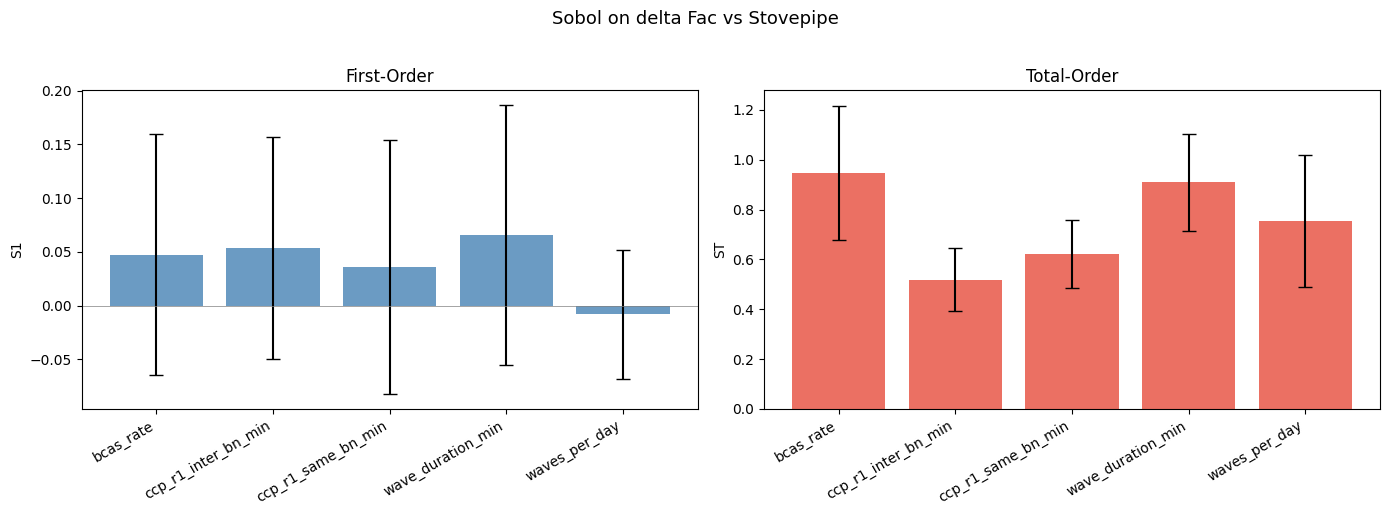

                         S1  S1_conf     ST  ST_conf
bcas_rate            0.0473   0.1121 0.9473   0.2704
ccp_r1_inter_bn_min  0.0532   0.1034 0.5184   0.1256
ccp_r1_same_bn_min   0.0359   0.1187 0.6225   0.1361
wave_duration_min    0.0656   0.1214 0.9089   0.1947
waves_per_day       -0.0082   0.0602 0.7546   0.2660


In [2]:
Si = sobol_analyze.analyze(problem, delta, calc_second_order=True, print_to_console=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
x_pos = np.arange(len(UNCERTAINTIES_SORTED))

axes[0].bar(x_pos, Si["S1"], yerr=Si["S1_conf"], capsize=5, color="steelblue", alpha=0.8)
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(UNCERTAINTIES_SORTED, rotation=30, ha="right")
axes[0].set_ylabel("S1")
axes[0].set_title("First-Order")
axes[0].axhline(0, color="grey", linewidth=0.5)

axes[1].bar(x_pos, Si["ST"], yerr=Si["ST_conf"], capsize=5, color="#e74c3c", alpha=0.8)
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(UNCERTAINTIES_SORTED, rotation=30, ha="right")
axes[1].set_ylabel("ST")
axes[1].set_title("Total-Order")
axes[1].axhline(0, color="grey", linewidth=0.5)

fig.suptitle("Sobol on delta Fac vs Stovepipe", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

print(pd.DataFrame({"S1": Si["S1"], "S1_conf": Si["S1_conf"], "ST": Si["ST"], "ST_conf": Si["ST_conf"]}, index=UNCERTAINTIES_SORTED).to_string(float_format="%.4f"))


## S2 — Pairwise Interactions


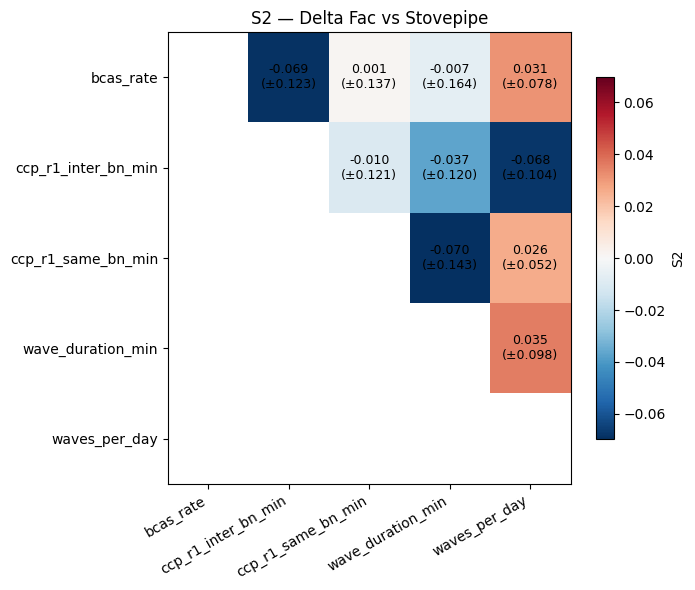

In [3]:
S2 = pd.DataFrame(Si["S2"], index=UNCERTAINTIES, columns=UNCERTAINTIES_SORTED)
S2_conf = pd.DataFrame(Si["S2_conf"], index=UNCERTAINTIES, columns=UNCERTAINTIES_SORTED)

fig, ax = plt.subplots(figsize=(7, 6))
mask = np.tril(np.ones_like(S2, dtype=bool), k=0)
s2_masked = S2.where(~mask)
vabs = max(0.01, np.nanmax(np.abs(s2_masked.values.astype(float))))
im = ax.imshow(s2_masked.values.astype(float), cmap="RdBu_r", vmin=-vabs, vmax=vabs, aspect="auto")
ax.set_xticks(range(len(UNCERTAINTIES_SORTED)))
ax.set_xticklabels(UNCERTAINTIES_SORTED, rotation=30, ha="right")
ax.set_yticks(range(len(UNCERTAINTIES_SORTED)))
ax.set_yticklabels(UNCERTAINTIES_SORTED)
ax.set_title("S2 — Delta Fac vs Stovepipe")
for i in range(len(UNCERTAINTIES_SORTED)):
    for j in range(len(UNCERTAINTIES_SORTED)):
        if not mask[i, j]:
            v = S2.iloc[i, j]
            c = S2_conf.iloc[i, j]
            if not np.isnan(v):
                ax.text(j, i, f"{v:.3f}\n(\u00b1{c:.3f})", ha="center", va="center", fontsize=9)
plt.colorbar(im, ax=ax, shrink=0.8, label="S2")
plt.tight_layout()
plt.show()
